# Logistic Regression

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. What is Logistic Regression?

Logistic Regression models the relationship between a **binary outcome** $y$ (0 or 1) and one or more predictors ($x_1, \dots, x_p$).

- Instead of predicting $y$ directly, it predicts the **probability** that $y = 1$.
- Linear regression would predict values below 0 or above 1; logistic regression keeps predictions in $(0, 1)$.
- The model is linear on the **log-odds (logit)** scale:

$$
\text{logit}(p) = \log \frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p, \qquad p = P(y=1 \mid x_1, \dots, x_p)
$$

## 2. From Logit to Probability

$$
p = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}}
$$

- $\beta_j > 0$ → the predictor increases the probability of $y=1$
- $\beta_j < 0$ → the predictor decreases it
- $\beta_j = 0$ → no effect

### Odds Ratios
The **odds** are $\frac{p}{1-p}$. Exponentiating a coefficient gives an **odds ratio**: $e^{\beta_j}$ is the factor by which the odds multiply for each one-unit increase in $x_j$.

## 3. Estimation and Testing

- Coefficients are estimated via **Maximum Likelihood Estimation (MLE)**, not OLS.
- $H_0: \beta_j = 0$ is tested with a **Wald z-test** (in `summary()`) or a **likelihood-ratio test** (`anova(..., test = "Chisq")`).

> **Pitfall — perfect separation:** if one value of $x$ perfectly splits the 0s from the 1s (e.g. everyone who studied ≤ 5 hours failed and everyone above passed), the MLE does not exist: the coefficients run off to infinity and R warns *"fitted probabilities numerically 0 or 1 occurred"*. Real data almost always overlap; if yours don't, consider penalised (Firth) logistic regression.

In [2]:
# Example: pass/fail vs study hours for 40 students (with realistic overlap)
set.seed(21)
study_hours <- round(runif(40, 1, 12), 1)
true_p <- plogis(-4 + 0.7 * study_hours)
pass_exam <- rbinom(40, 1, true_p)
logit_data <- data.frame(Study = study_hours, Pass = pass_exam)

cat("Pass rate:", mean(logit_data$Pass), "\n")
logit_model <- glm(Pass ~ Study, data = logit_data, family = binomial)
summary(logit_model)

Pass rate: 0.6 



Call:
glm(formula = Pass ~ Study, family = binomial, data = logit_data)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept)  -3.1408     1.1193  -2.806 0.005016 ** 
Study         0.5196     0.1541   3.372 0.000746 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 53.841  on 39  degrees of freedom
Residual deviance: 35.979  on 38  degrees of freedom
AIC: 39.979

Number of Fisher Scoring iterations: 4


In [3]:
b <- coef(logit_model)
cat("Odds ratio per extra study hour: exp(beta1) =", round(exp(b["Study"]), 3), "\n")
cat("95% CI for the odds ratio      :", round(exp(confint.default(logit_model)["Study", ]), 3), "\n")
cat("Hours needed for a 50% pass probability: -beta0/beta1 =", round(-b[1] / b[2], 2), "\n\n")

new <- data.frame(Study = c(2, 5, 8, 11))
new$P_pass <- round(predict(logit_model, new, type = "response"), 3)
print(new, row.names = FALSE)

cat("\nLikelihood-ratio test vs the intercept-only model:\n")
anova(glm(Pass ~ 1, data = logit_data, family = binomial), logit_model, test = "Chisq")

Odds ratio per extra study hour: exp(beta1) = 1.681 


95% CI for the odds ratio      : 1.243 2.274 


Hours needed for a 50% pass probability: -beta0/beta1 = 6.05 



 Study P_pass
     2  0.109
     5  0.367
     8  0.734
    11  0.929



Likelihood-ratio test vs the intercept-only model:


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,39,53.84093,NA,NA,NA
2,38,35.97904,1,17.8619,2.375297e-05


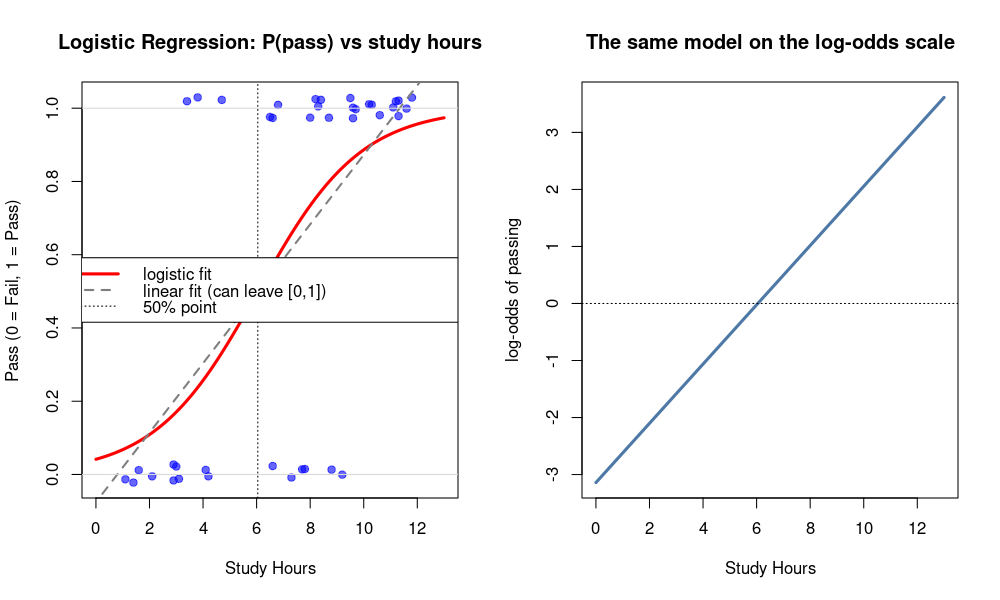

In [4]:
par(mfrow = c(1, 2))
plot(logit_data$Study, jitter(logit_data$Pass, 0.15), pch = 19, col = adjustcolor("blue", 0.6),
     xlab = "Study Hours", ylab = "Pass (0 = Fail, 1 = Pass)", xlim = c(0, 13),
     main = "Logistic Regression: P(pass) vs study hours")
curve(predict(logit_model, newdata = data.frame(Study = x), type = "response"),
      add = TRUE, col = "red", lwd = 3)
abline(lm(Pass ~ Study, data = logit_data), col = "grey50", lty = 2, lwd = 2)
abline(h = c(0, 0.5, 1), col = "grey85")
abline(v = -b[1] / b[2], lty = 3)
legend("right", c("logistic fit", "linear fit (can leave [0,1])", "50% point"), bg = "white",
       col = c("red", "grey50", "black"), lty = c(1, 2, 3), lwd = c(3, 2, 1))

curve(b[1] + b[2] * x, 0, 13, lwd = 3, col = "#4E79A7",
      main = "The same model on the log-odds scale", xlab = "Study Hours", ylab = "log-odds of passing")
abline(h = 0, lty = 3)

## 4. Evaluating the Classifier

To turn probabilities into decisions we pick a **threshold** (0.5 by default) and build a **confusion matrix**.

In [5]:
logit_data$Prob <- predict(logit_model, type = "response")
logit_data$Predicted <- ifelse(logit_data$Prob > 0.5, 1, 0)

cm <- table(Predicted = logit_data$Predicted, Actual = logit_data$Pass)
print(cm)
TP <- cm["1", "1"]; TN <- cm["0", "0"]; FP <- cm["1", "0"]; FN <- cm["0", "1"]
cat("\nAccuracy   :", round((TP + TN) / sum(cm), 3), "\n")
cat("Sensitivity:", round(TP / (TP + FN), 3), " (share of passers correctly identified)\n")
cat("Specificity:", round(TN / (TN + FP), 3), " (share of failers correctly identified)\n")

         Actual
Predicted  0  1
        0 10  3
        1  6 21



Accuracy   : 0.775 


Sensitivity: 0.875  (share of passers correctly identified)


Specificity: 0.625  (share of failers correctly identified)


## 5. Why Perfect Separation Breaks the Model

The original toy example of this lesson (everyone with ≤ 5 hours fails, everyone above passes) shows what goes wrong:

In [6]:
toy <- data.frame(Study = 2:10, Pass = c(0, 0, 0, 0, 1, 1, 1, 1, 1))
toy_fit <- suppressWarnings(glm(Pass ~ Study, data = toy, family = binomial))
cat("Converged:", toy_fit$converged, "\n")
print(round(summary(toy_fit)$coefficients, 2))
cat("Huge coefficients and standard errors -> the slope is effectively infinite (a step function).\n")

Converged: FALSE 


            Estimate Std. Error z value Pr(>|z|)
(Intercept)  -248.42   380171.0       0        1
Study          45.16    68704.8       0        1


Huge coefficients and standard errors -> the slope is effectively infinite (a step function).


*Insight: Perfect separation sounds like good news (a perfect predictor!), but it means the data cannot pin down **how steep** the curve is. With more data the overlap usually appears; until then, the reported coefficients and p-values are meaningless.*

## Real-World Use Case or Analogy

Imagine predicting whether a student passes an exam from study hours:

- Points on the plot: each student's result (pass = 1, fail = 0).
- Red curve: the predicted probability of passing.
- The odds ratio says how much each extra hour multiplies the odds of passing.

The same model is used in **medicine** (presence or absence of a disease from risk factors), **banking** (will a customer default on a loan?) and **marketing** (will a user click the ad?). In each case, the probability is often more useful than the yes/no prediction: a bank may still lend at a 10% default risk, but charge a higher interest rate.